# Jointly Impacted Constraints - Coordination Approaches

> **Work in progress** — an illustrative teaching notebook under active development, not an authoritative reference.

204 shows the mechanics of jointly impacted constraints on a shared network:
flow superposition, accommodation, and reconciliation. This notebook defines
the jointly impacted constraint, the qualifying criterion that selects one
for coordination in both markets, and the two mechanism families that divide
it. The two mechanism families are:

1. **The firm flow entitlement** divides the transmission element. Each
   market holds a standing quota on each coordinated element and always
   dispatches within that quota, so the superposition is feasible by
   construction. The Eastern joint operating agreements are the entitlement's
   lineage: coordinated flowgates settled against firm flow entitlements,
   with market-to-market redispatch layered on top.
2. **The freeze-and-share rule** divides the relief. There is no standing
   allocation. When a study finds an element nearing its limit, both markets
   activate the element at their own studied flows, which in operating
   practice is a "do-not-exacerbate" obligation, and any relief the study
   requires is split by an agreed share. The West's unscheduled-flow relief
   practice, which allocates curtailment obligations from current flows when
   a path is stressed, is the freeze-and-share lineage.

Both rules run on the same draws, and the notebook exhibits four failure
modes:

1. The quota's **phantom congestion**, a binding constraint on a line with
   physical headroom.
2. Freeze-and-share's **detection risk**. A missed study sends the overload
   to real time, where relief is out-of-market curtailment at a premium.
3. Freeze-and-share's **baseline incentive**. The market that was loading the
   line at the freeze keeps more of it.
4. Freeze-and-share's **non-economic relief**. Proportional shares back both
   markets down regardless of whose redispatch is cheaper.

The running example is 204's: `line_4` (buses 6–7) rated 40 MW, internal to
Market A. 205 takes the interchange side of the same seam. Everything runs on
the shared libraries: `wscc9_model`, `footprints`, `seams_engine`,
`wscc9_figures`, and `risk`.


## 0. Setup


In [1]:
#@title ▶ Run me first — Colab setup (installs packages, fetches the helper modules)
# On Google Colab this installs the few non-default packages and downloads the
# helper modules next to the notebook. Running locally it does nothing
# (the modules are already on disk), so the same notebook works in both places.
import sys, subprocess

def _sh(cmd):
    print("$", cmd)
    subprocess.run(cmd, shell=True, check=True)

if "google.colab" in sys.modules:
    _sh("pip install -q pypsa pandapower pycirclize")
    _base = "https://raw.githubusercontent.com/pdockery/wscc9-illustrative-model/main"
    for _f in ("ieee9_network.py", "seams_engine.py", "nodal_plot.py",
               "wscc9_model.py", "footprints.py", "revenue_allocation.py",
               "wscc9_figures.py", "atc.py", "risk.py", "bilateral.py", "seam_views.py"):
        _sh(f"wget -q {_base}/{_f} -O {_f}")
    print("Colab setup complete.")
else:
    print("Local run: using the modules already in this folder.")


Local run: using the modules already in this folder.


In [2]:
import sys, os, importlib, copy
import warnings; warnings.filterwarnings('ignore')
import logging; logging.getLogger('pypsa').setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath('.'))

# Teaching libraries for the WSCC 9-bus illustrative repository.
import seams_engine, nodal_plot, wscc9_model, footprints, revenue_allocation, wscc9_figures, risk
for _m in (seams_engine, nodal_plot, wscc9_model, footprints, revenue_allocation, wscc9_figures, risk):
    importlib.reload(_m)
import wscc9_model as wm, footprints as fpmod, revenue_allocation as ra, wscc9_figures as figs
from wscc9_model import (
    build_network, make_engine, shift_factors, sf_table,
    BUS_COLORS, COORDS, RING_ORDER, ROTATION_DEG, CENTER_BUS,
)
from seams_engine import (
    compute_ptdf, MarketEngine, solve_engine_dispatch,
    physical_flows, to_supply_demand, susceptance_widths,
)
from nodal_plot import plot_network_topology, plot_combined_letter
pd.set_option('display.width', 160)

figs.install_latex_repr()   # booktabs LaTeX repr for DataFrames on PDF export

print('ready')

ready

In [3]:
# The teaching fleet and loads live in wscc9_model. Market B gets a
# second unit so the neighbor can REDISPATCH against a cap rather than only
# shed -- both coordination rules act by capping flows, and a one-unit book has
# no dispatch response to a cap.
GEN_FLEET = dict(wm.DEFAULT_GEN_FLEET)   # {gen: {bus, cost $/MWh, p_nom MW}}
GEN_FLEET['gen_B5'] = {'bus': '5', 'cost': 55.0, 'p_nom': 150.0}
LOADS     = dict(wm.DEFAULT_LOADS)       # {bus: MW}
print('loads (MW):', LOADS)
pd.DataFrame(GEN_FLEET).T[['bus', 'cost', 'p_nom']]

loads (MW):

{'5': 90.0, '7': 100.0, '9': 125.0}

,bus,cost,p_nom
gen_slack_0,1,50.0,250.0
gen_0,2,35.0,300.0
gen_1,3,20.0,170.0
gen_B5,5,55.0,150.0


In [4]:
## -- EDIT -- the two market footprints, monitored/activated sets, ratings.
MKT_DEFS = {
    'Market A': ['2', '8', '7', '6', '3'],   # cheap fleet (bus 3 $20, bus 2 $35)
    'Market B': ['1', '9', '4', '5'],         # bus-1 unit ($50) + bus-5 unit ($55)
}
MARKET_COLORS = {'Market A': '#993AFF', 'Market B': '#2471A3'}
MONITORED_LINES = {   # M^M_mon -- the lines each market models and watches
    'Market A': ['line_2', 'line_3', 'line_4', 'line_5', 'line_6'],
    'Market B': ['line_0', 'line_1', 'line_7', 'line_8'],
}
ACTIVATED_LINES = {   # M^M_act -- the monitored lines whose limits enter the clearing
    'Market A': ['line_2', 'line_3', 'line_4', 'line_5', 'line_6'],
    'Market B': ['line_0', 'line_1', 'line_7', 'line_8'],
}
LINE_RATINGS = {'line_4': 40.0}   # the running example: line_4 (6-7), the coordinated element
L4 = 'line_4'
# ---------------------------------------------------------------------------
net = build_network(LINE_RATINGS)
pt  = compute_ptdf(net, slack_bus='1')
fp  = fpmod.make(pt, MKT_DEFS, MARKET_COLORS, monitored=MONITORED_LINES, tie_label='intertie')
mkt_of = fp.fp_of
seam_lines = fp.ties

def engine_A(load7=None):
    eng = make_engine('Market A', MKT_DEFS['Market A'], gen_fleet=GEN_FLEET,
                      activated=ACTIVATED_LINES['Market A'])
    if load7 is not None:
        eng.loads['7'] = float(load7)
    return eng

def engine_B(load9=None, cost5=None):
    eng = make_engine('Market B', MKT_DEFS['Market B'], gen_fleet=GEN_FLEET,
                      activated=ACTIVATED_LINES['Market B'])
    if load9 is not None:
        eng.loads['9'] = float(load9)
    if cost5 is not None:
        eng.gens['gen_B5']['cost'] = float(cost5)
    return eng

def bill(r):
    # the full bill: production cost plus the shed penalty (total_cost alone
    # omits shed, so a choked clearing could misread as cheap)
    return r.total_cost + 150.0 * sum(r.shed_by_bus.values())

def clear_capped(eng, cap, line=L4):
    # A per-engine rating: the engine sees ITS OWN cap on the coordinated line.
    pt_m = copy.deepcopy(pt)
    pt_m.s_nom[pt_m.line_idx[line]] = max(float(cap), 1e-6)
    eng.activated_lines = sorted(set(eng.activated_lines) | {line})
    return solve_engine_dispatch(pt_m, eng, shed_price=150.0)

def unified(load7=None, load9=None, cost5=None):
    gens = {g: dict(s) for g, s in GEN_FLEET.items()}
    if cost5 is not None:
        gens['gen_B5']['cost'] = float(cost5)
    loads = dict(LOADS)
    if load7 is not None: loads['7'] = float(load7)
    if load9 is not None: loads['9'] = float(load9)
    eng = MarketEngine(name='unified', gens=gens, loads=loads, activated_lines='all')
    return solve_engine_dispatch(pt, eng, shed_price=150.0)

print('engines ready; the coordinated element is', L4,
      f'({pt.line_buses[pt.line_idx[L4]][0]}-{pt.line_buses[pt.line_idx[L4]][1]}, '
      f'{pt.s_nom[pt.line_idx[L4]]:.0f} MW), internal to Market A')

INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines


engines ready; the coordinated element is

line_4

(6-7, 40 MW), internal to Market A

In [5]:
# == The exhibit layer: one-unit Market B, and the three frames ================
# Every exhibit in this notebook is drawn the same way: Market A's view, Market
# B's view, then the combined power flow -- twice, as the network + nodal
# dispatch letter and as the standalone network with net injection/withdrawal
# annotations at every bus.
#
# Two fleets live side by side, on purpose:
#   * GEN_FLEET_P (below) -- Market B as a ONE-UNIT book: the bus-1 unit raised
#     250 -> 300 MW, and its only outlet line_0 (1-4) raised with it. Used
#     wherever B is not capped (section 2), where the second unit adds
#     nothing but clutter.
#   * GEN_FLEET (section 0) -- B's second unit at bus 5. Freeze-and-share caps
#     B, and a one-generation-bus book has no flow lever: its loop flow is fixed
#     by its load, so a cap can only be met by curtailment. Section 3 keeps the
#     two-unit fleet so B can REDISPATCH against the cap, which is the mechanism
#     that section is about.
GEN_FLEET_P = {g: dict(s) for g, s in wm.DEFAULT_GEN_FLEET.items()}
GEN_FLEET_P['gen_slack_0']['p_nom'] = 300.0     # the bus-1 unit, 250 -> 300
RATINGS_P = dict(LINE_RATINGS); RATINGS_P['line_0'] = 300.0
net_P = build_network(RATINGS_P)
pt_P  = compute_ptdf(net_P, slack_bus='1')
fp_P  = fpmod.make(pt_P, MKT_DEFS, MARKET_COLORS,
                   monitored=MONITORED_LINES, tie_label='intertie')

def engine_A_P(load7=None):
    eng = make_engine('Market A', MKT_DEFS['Market A'], gen_fleet=GEN_FLEET_P,
                      activated=ACTIVATED_LINES['Market A'])
    if load7 is not None:
        eng.loads['7'] = float(load7)
    return eng

def engine_B_P(load9=None):
    eng = make_engine('Market B', MKT_DEFS['Market B'], gen_fleet=GEN_FLEET_P,
                      activated=ACTIVATED_LINES['Market B'])
    if load9 is not None:
        eng.loads['9'] = float(load9)
    return eng

def clear_capped_P(eng, cap, line=L4):
    # A per-engine rating on the exhibit network: the engine sees ITS OWN cap.
    pt_m = copy.deepcopy(pt_P)
    pt_m.s_nom[pt_m.line_idx[line]] = max(float(cap), 1e-6)
    eng.activated_lines = sorted(set(eng.activated_lines) | {line})
    return solve_engine_dispatch(pt_m, eng, shed_price=150.0)

def unified_P(load7=None, load9=None):
    gens = {g: dict(s) for g, s in GEN_FLEET_P.items()}
    loads = dict(LOADS)
    if load7 is not None: loads['7'] = float(load7)
    if load9 is not None: loads['9'] = float(load9)
    eng = MarketEngine(name='unified', gens=gens, loads=loads, activated_lines='all')
    return solve_engine_dispatch(pt_P, eng, shed_price=150.0)

import os
SAVE_EXPORTS = 'google.colab' not in sys.modules   # skip the file writes on Colab
EXPORT_DIR  = 'presentation_exhibits'   # PNGs and CSVs together
EXPORT_SIZE     = (13.33, 7.5)  # two-panel figures: a full 16:9 slide, inches
NET_EXPORT_SIZE = (7.5, 7.5)    # standalone networks: square, fits the graph
PANEL_EXPORT_SIZE = (6.67, 7.5)  # a letter panel at its share of the page:
                                 # half the 13.33 x 7.5 canvas, so text keeps
                                 # the proportions it has inside the letter
EXPORT_DPI      = 600           # -> 7998 x 4500 px and 4500 x 4500 px

# ---- the frames live in seam_views.py; context set once, names aliased ------
import seam_views as sv
importlib.reload(sv)
sv.configure(fp=fp_P, gen_fleet=GEN_FLEET_P, loads=LOADS,
             save_enabled=SAVE_EXPORTS, export_dir=EXPORT_DIR, export_dpi=EXPORT_DPI,
             export_size=EXPORT_SIZE, net_export_size=NET_EXPORT_SIZE,
             panel_export_size=PANEL_EXPORT_SIZE)
own_view, forecast_view = sv.own_view, sv.forecast_view
combined_views, export_pair, save_clean = sv.combined_views, sv.export_pair, sv.save_clean

print('exhibit layer ready (frames from seam_views.py)')


INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines


exhibit layer ready

## 1. The jointly impacted constraint and the two rules

**Nomenclature.** Sets are script capitals; an element is the matching
lower-case letter (upper-case for markets). The `Code` column is where each
object lives in the shared libraries.

| Symbol | Code | Definition |
|---|---|---|
| $\mathcal N$, $\mathcal M$ | `pt.buses` / `pt.lines` | buses, and the **network line set** — every line in the shared network |
| $SF_{n,m}$, $\bar F_m$ | `shift_factors()` / `LINE_RATINGS` | shift factor of bus $n$ on line $m$; line $m$'s rating |
| $\mathcal E$, $M$ | `make_engine` | the set of market engines; $M\in\mathcal E=\{A,B\}$ |
| $\mathcal M^{M}_{\text{mon}}$, $\mathcal M^{M}_{\text{act}}$ | `MONITORED_LINES` / `ACTIVATED_LINES` | market $M$'s monitored lines, and the activated constraint set whose limits it enforces |
| $F^{M}_m$, $F^{s}_m$ | `res.flow_own` / `physical_flows` | market $M$'s **flow contribution** on line $m$; the superposed flow $\sum_M F^{M}_m$ |
| $\mu^{M}_m$ | `res.line_dual` | market $M$'s signed dual on line $m$ — under a cap, the cap's shadow price |
| $q^{M}_m$ | `QUOTA` | market $M$'s **firm flow entitlement** (quota) on coordinated line $m$ |
| $\hat F^{M}_m$, $\hat\Delta_m$ | `study flows` | the study's flow for market $M$, and the studied exceedance $(|\hat F^{s}_m|-\bar F_m)^{+}$ |
| $F^{M}_m(0)$ | `BASELINE` | the freeze **baseline** — studied/advisory flows, or the prior interval's actuals |
| $\tau$ | `TAU` | the qualification threshold — the share of the rating the neighboring market's flow contribution must reach for joint activation |
| $\kappa$ | `TRIGGER_FRAC` | the trigger threshold — a studied loading at or above $\kappa\bar F_m$ arms the rule |
| $\sigma_M$ | `SIGMA` | market $M$'s relief share, $\sum_M\sigma_M=1$ |
| $b$, $\pi$ | `BLOCK_MW` / `RT_PREMIUM` | the out-of-market curtailment block, and the real-time premium |
| $C^{\text{uni}}$ | `unified()` | the unified clearing's production cost — the benchmark |

A **jointly impacted constraint** is a transmission element that both markets
activate and that has flow contribution from both market footprints,

$$m \in \mathcal M^{A}_{\text{act}} \cap \mathcal M^{B}_{\text{act}},\qquad F^{A}_m \neq 0,\quad F^{B}_m \neq 0. \tag{1}$$

*In words.* Line $m$ is in Market A's activated constraint set
$\mathcal M^{A}_{\text{act}}$ and in Market B's activated constraint set
$\mathcal M^{B}_{\text{act}}$, Market A's flow contribution $F^{A}_m$ on
line $m$ is nonzero, and Market B's flow contribution $F^{B}_m$ on line $m$
is nonzero.

Activation in both markets carries a qualifying criterion: the neighboring
market's gen-to-load flow contribution on the element must exceed a scalar
threshold,

$$\big|F^{M'}_m\big| \;\ge\; \tau\,\bar F_m,\qquad M'\neq M. \tag{2}$$

*In words.* Element $m$ qualifies for activation in market $M$'s set when the
magnitude of the neighboring market $M'$'s flow contribution
$\big|F^{M'}_m\big|$ meets or exceeds the qualification threshold $\tau$
times line $m$'s rating $\bar F_m$, for the market $M'$ other than market $M$.

Applied in both directions, (2) selects the elements both markets activate in
(1).

Activation in both markets does not decide the limit each market enforces on
its own contribution. The two rules below are the two families of that
choice. The quota holds (1) standing, in every clearing. Freeze-and-share
activates the element only when a study arms the rule.

**The firm flow entitlement (the market quota)** is a standing partition of the
coordinated element, enforced in every clearing, stressed or not:

$$F^{M}_m \;\le\; q^{M}_m\quad\forall M\in\mathcal E,\qquad \sum_{M\in\mathcal E} q^{M}_m \;=\; \bar F_m. \tag{3}$$

*In words.* Market $M$'s own flow contribution $F^{M}_m$ on coordinated line
$m$ stays within its firm flow entitlement $q^{M}_m$, for every market $M$ in
the engine set $\mathcal E$. The entitlements $q^{M}_m$ sum over the engine
set to line $m$'s rating $\bar F_m$.

Because the entitlements sum to the rating, the superposed flow is within
the rating no matter what either market does. Feasibility holds by
construction. Each engine enforces its entitlement as a private rating on its own copy of
the line (the `clear_capped` helper). The scope of this notebook does not
include the Eastern settlement form, in which market flow may exceed the
entitlement and the deviation settles at a relief price.

The quota's failure state is **phantom congestion**:

$$F^{M}_m \;=\; q^{M}_m,\qquad \mu^{M}_m \neq 0,\qquad \big|F^{s}_m\big| \;<\; \bar F_m. \tag{4}$$

*In words.* Market $M$'s own flow contribution $F^{M}_m$ sits at its
entitlement $q^{M}_m$, the signed dual $\mu^{M}_m$ on line $m$ is nonzero,
and the superposed flow $|F^{s}_m|$ is below line $m$'s rating $\bar F_m$.

A binding, priced constraint sits on a line with physical headroom. The
scarcity is contractual, not physical. 222's SP-Tie placement artifact is
the same phenomenon, a constraint binding in a representation while the line
itself has room.

**Freeze-and-share** is event-triggered. Nothing stands until a study finds
the element nearing its limit, $|\hat F^{s}_m| \ge \kappa\bar F_m$. Then
each market is capped at its baseline flow less its share of the studied
exceedance:

$$F^{M}_m \;\le\; F^{M}_m(0) \;-\; \sigma_M\,\hat\Delta_m,\qquad \sum_{M\in\mathcal E}\sigma_M \;=\; 1. \tag{5}$$

*In words.* On an activated line $m$, market $M$'s own flow contribution
$F^{M}_m$ is capped at its baseline $F^{M}_m(0)$ less its relief share
$\sigma_M$ of the studied exceedance $\hat\Delta_m$. The relief shares
$\sigma_M$ sum over the engine set to one.

No market may increase its loading on a stressed element beyond its baseline,
and each engine implements only its own cap. A market does not dispatch
another market's flows.

When the study finds an exceedance, the caps reassemble the rating exactly:

$$\sum_{M\in\mathcal E}\Big(F^{M}_m(0) - \sigma_M\,\hat\Delta_m\Big) \;=\; \big|\hat F^{s}_m(0)\big| - \hat\Delta_m \;=\; \bar F_m. \tag{6}$$

*In words.* Summed over the engine set, the baselines $F^{M}_m(0)$ add up to
the studied superposition $|\hat F^{s}_m(0)|$, and the relief shares
$\sigma_M$ of the studied exceedance add up to the whole exceedance
$\hat\Delta_m$. The difference between the two is line $m$'s rating
$\bar F_m$.

Two elements of the rule are design choices. The **baseline** $F^{M}_m(0)$ is
either the studied or advisory flows, which are a forecast, or the prior
interval's actual flows, which are a fact, and the incentives differ between
the two. The **relief shares** $\sigma_M$ allocate relief quantity only. Each
market bears the redispatch cost of its own share and no compensation crosses
the seam, so the shares back both markets down regardless of whose redispatch
is cheaper.


In [6]:
# -- EDIT -- the qualification threshold ---------------------------------------
TAU = 0.05   # tau: share of the rating the neighbor's contribution must reach
# --------------------------------------------------------------------------------
# The criterion (2) on the running example: each market's gen-to-load flow
# contribution on line_4 in a blind reference clear. A market's contribution
# qualifies the element for the OTHER market's activated set.
rA_q = solve_engine_dispatch(pt, engine_A(), shed_price=150.0)
rB_q = solve_engine_dispatch(pt, engine_B(), shed_price=150.0)
RATE_Q = float(pt.s_nom[pt.line_idx[L4]])
rows_q = []
for mkt, res in (('Market A', rA_q), ('Market B', rB_q)):
    f = abs(res.flow_own[L4])
    rows_q.append({'contributing market': mkt,
                   f'flow contribution on {L4} (MW)': round(f, 1),
                   'share of rating': round(f / RATE_Q, 3),
                   f'meets tau = {TAU:.2f}': bool(f >= TAU * RATE_Q)})
quali = all(abs(r.flow_own[L4]) >= TAU * RATE_Q for r in (rA_q, rB_q))
print(f'{L4} qualifies as a jointly impacted constraint at tau = {TAU:.2f}: {quali}')
pd.DataFrame(rows_q).set_index('contributing market')


line_4 qualifies as a jointly impacted constraint at tau = 0.05: True

,flow contribution on line_4 (MW),share of rating,meets tau = 0.05
contributing market,,,
Market A,40.0,1.000,True
Market B,3.4,0.086,True


In [7]:
# The quota inherits a baseline year: each market's share of the coordinated
# element in a reference blind clear at nominal drivers -- the freeze-date
# genealogy of every entitlement.
rA_ref = solve_engine_dispatch(pt, engine_A(), shed_price=150.0)
rB_ref = solve_engine_dispatch(pt, engine_B(), shed_price=150.0)
fA0, fB0 = abs(rA_ref.flow_own[L4]), abs(rB_ref.flow_own[L4])
RATE = float(pt.s_nom[pt.line_idx[L4]])
QUOTA = {'Market A': round(RATE * fA0 / (fA0 + fB0), 1),
         'Market B': round(RATE * fB0 / (fA0 + fB0), 1)}
print(f'reference blind flows on {L4}: A {fA0:.1f} MW, B {fB0:.1f} MW '
      f'(superposed {fA0 + fB0:.1f} > rating {RATE:.0f})')
print(f'the baseline-year quota: q_A = {QUOTA["Market A"]}, q_B = {QUOTA["Market B"]} '
      f'(sums to the rating)')

reference blind flows on line_4: A 40.0 MW, B 3.4 MW (superposed 43.4 > rating 40)

the baseline-year quota: q_A = 36.8, q_B = 3.2 (sums to the rating)

## 2. The quota, run

The quota never produces an overload, because the superposition cannot exceed
the rating. Its costs accrue in the unstressed states, every state in which
one market does not need its share and the other market is capped while the
line has room. The constructed canonical case runs first: the neighboring
market's large load runs low, its flow contribution on the coordinated element
falls, and the host market binds at its quota while the line has headroom.


In [8]:
# The canonical phantom case: B light (bus-9 load 75 MW instead of 125), drawn
# on the exhibit layer's one-unit Market B. B's quota is slack here -- the
# phantom is entirely A's cap binding while the line still has headroom -- so
# the second unit at bus 5 would add nothing to the picture.
L9_LIGHT = 75.0
A_q = engine_A_P()
B_q = engine_B_P(load9=L9_LIGHT)
rA_q = clear_capped_P(A_q, QUOTA['Market A'])
rB_q = clear_capped_P(B_q, QUOTA['Market B'])
r_u  = unified_P(load9=L9_LIGHT)

fs = rA_q.flow_own[L4] + rB_q.flow_own[L4]
head = RATE - abs(fs)
print(f"A's flow on {L4}: {rA_q.flow_own[L4]:.1f} at quota {QUOTA['Market A']}, "
      f"dual mu = {rA_q.line_dual[L4]:.2f} $/MWh (binding, priced)")
print(f"B's flow on {L4}: {rB_q.flow_own[L4]:.1f} of quota {QUOTA['Market B']} (unused share idle)")
print(f"superposed flow {fs:.1f} vs rating {RATE:.0f} -> {head:.1f} MW of PHYSICAL HEADROOM")
print()
rows = [
    {'arrangement': 'quota clears (A capped, B light)',
     'A bill ($/h)': round(bill(rA_q)), 'B bill ($/h)': round(bill(rB_q)),
     'sum': round(bill(rA_q) + bill(rB_q))},
    {'arrangement': 'unified clearing, same drivers',
     'A bill ($/h)': '--', 'B bill ($/h)': '--', 'sum': round(bill(r_u))},
]
display(pd.DataFrame(rows).set_index('arrangement'))
print(f'the phantom bill: {bill(rA_q) + bill(rB_q) - bill(r_u):,.0f} $/h '
      f'over the unified clearing, priced against a line with {head:.1f} MW to spare')


A's flow on line_4: 36.8 at quota 36.8, dual mu = -20.10 $/MWh (binding, priced)

B's flow on line_4: -2.8 of quota 3.2 (unused share idle)

superposed flow 34.0 vs rating 40 -> 6.0 MW of PHYSICAL HEADROOM

,A bill ($/h),B bill ($/h),sum
arrangement,,,
"quota clears (A capped, B light)",2973,8250,11223
"unified clearing, same drivers",--,--,7429


the phantom bill: 3,794 $/h over the unified clearing, priced against a line with 6.0 MW to spare

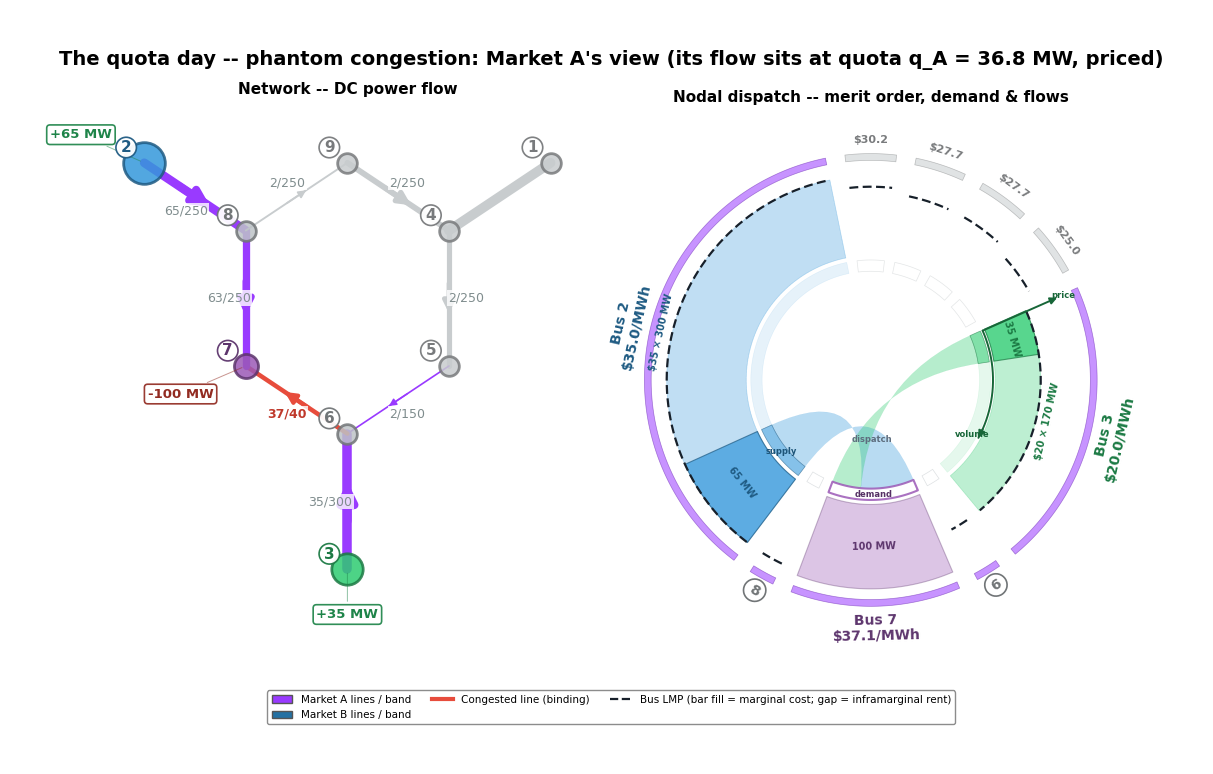

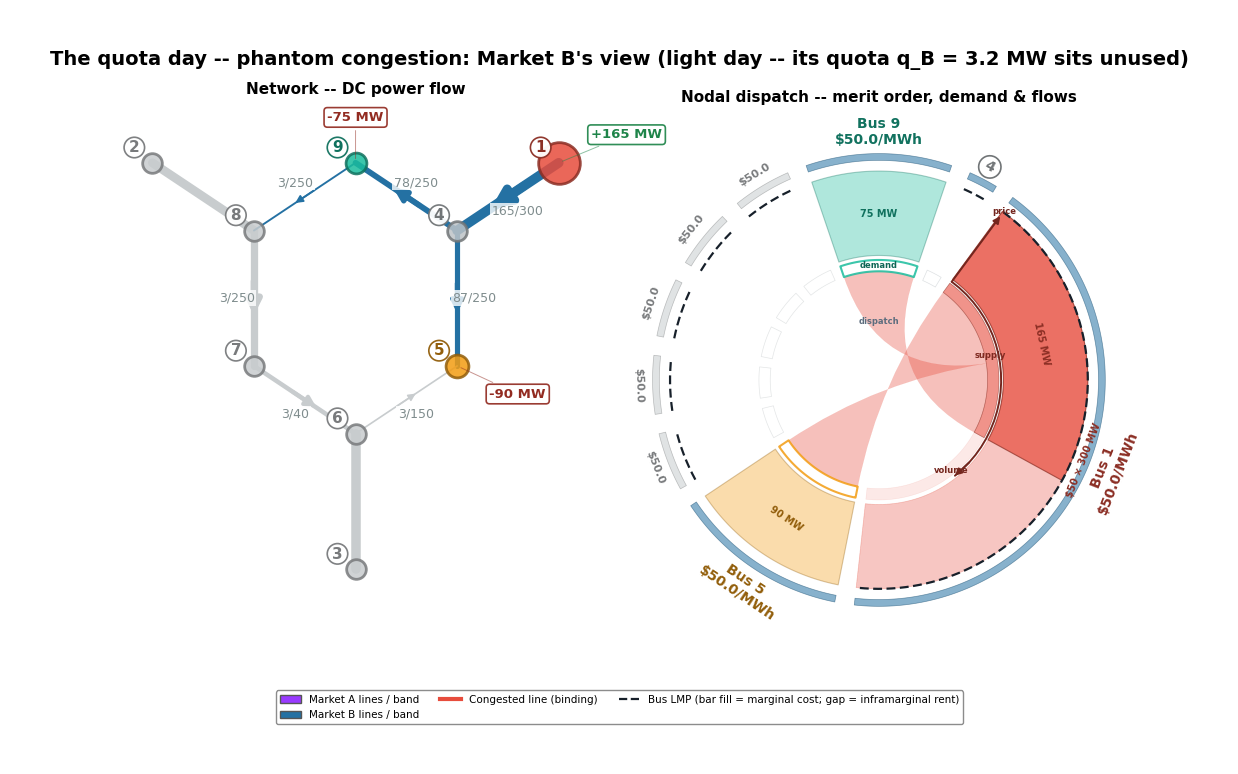

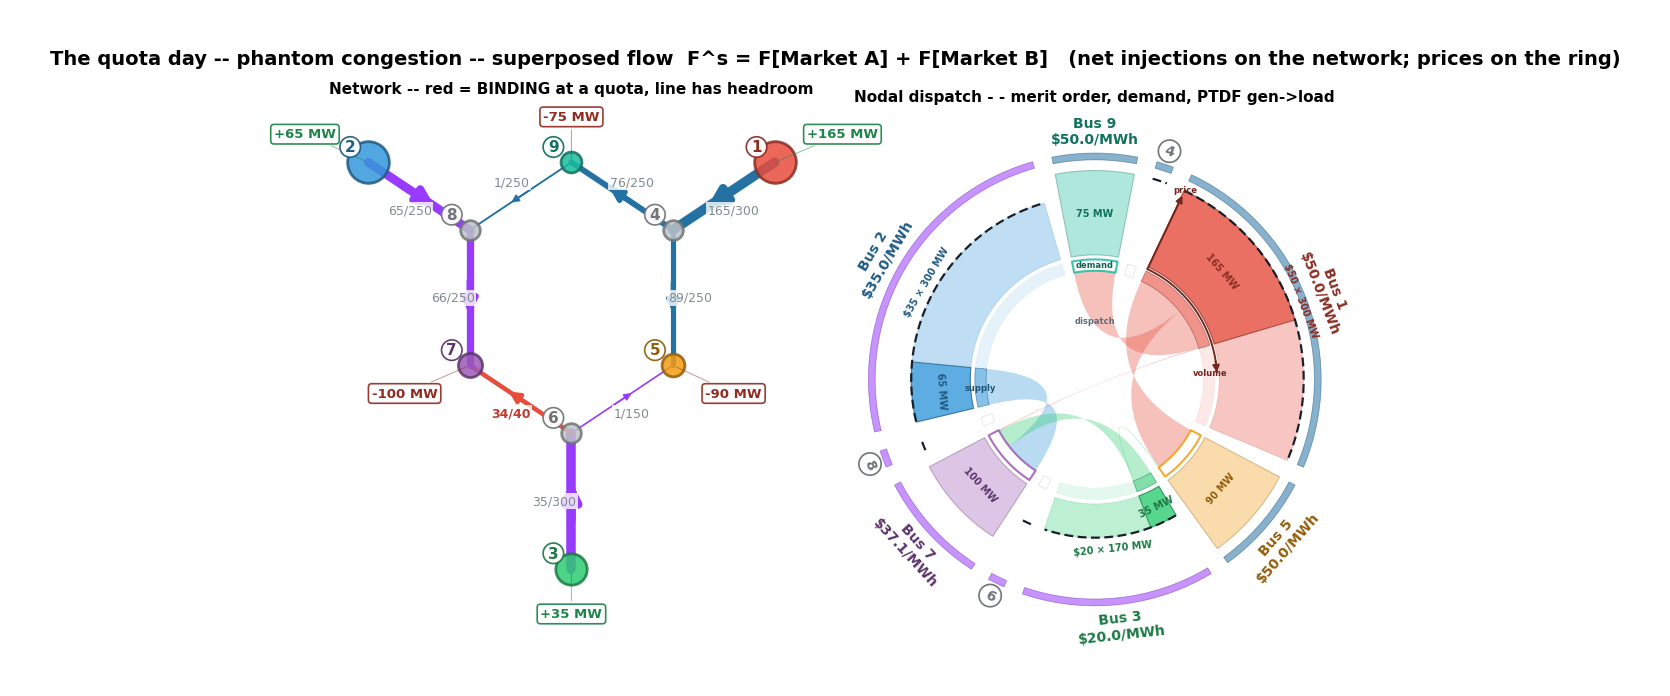

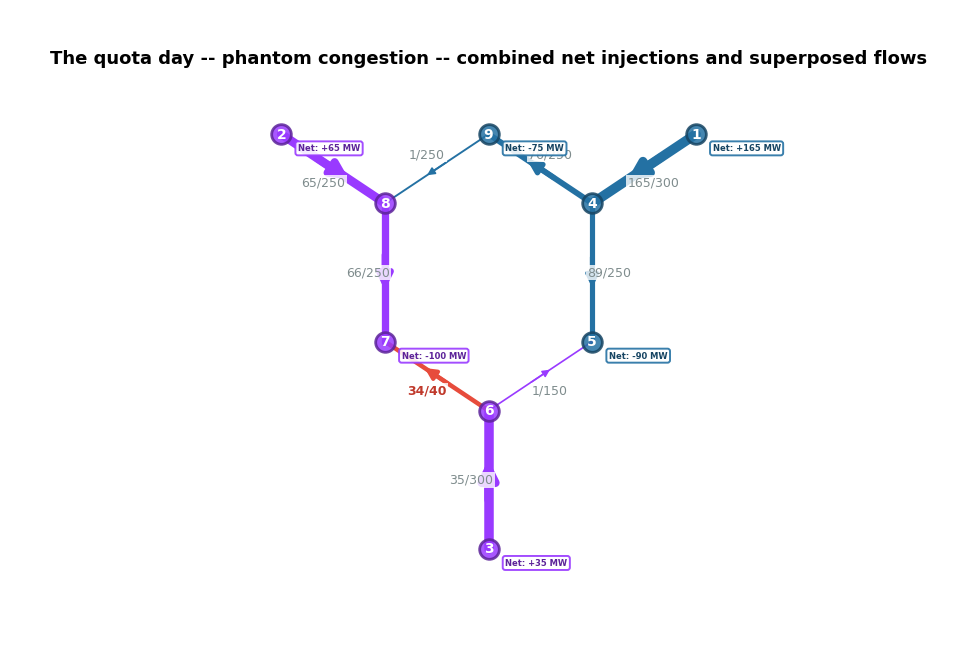

wrote presentation_exhibits\seams_cm_q_quota_phantom_settlement.csv and presentation_exhibits\seams_cm_q_quota_phantom_lines.csv

,market,LMP ($/MWh),gen (MW),paid to gen ($/h),load (MW),served (MW),paid by load ($/h)
bus,,,,,,,
1,Market B,50.0,165.0,8250.0,0.0,0.0,0.0
2,Market A,35.0,64.9,2269.9,0.0,0.0,0.0
3,Market A,20.0,35.1,702.9,0.0,0.0,0.0
4,Market B,50.0,0.0,0.0,0.0,0.0,0.0
5,Market B,50.0,0.0,0.0,90.0,90.0,4500.0
6,Market A,20.0,0.0,0.0,0.0,0.0,0.0
7,Market A,37.13,0.0,0.0,100.0,100.0,3712.6
8,Market A,35.0,0.0,0.0,0.0,0.0,0.0
9,Market B,50.0,0.0,0.0,75.0,75.0,3750.0


,from,to,F[Market A],F[Market B],F^s (MW),rating,loading_%,overload,book flow Market A (MW),|mu| Market A ($/MWh),rent Market A ($/h),book flow Market B (MW),|mu| Market B ($/MWh),rent Market B ($/h)
line,,,,,,,,,,,,,,
line_0,1,4,-0.0,165.0,165.0,300.0,55.0,False,-0.0,0.0,0.0,165.0,0.0,0.0
line_1,4,5,1.7,87.2,88.9,250.0,36.0,False,1.7,0.0,0.0,87.2,0.0,0.0
line_2,5,6,1.7,-2.8,-1.1,150.0,1.0,False,1.7,0.0,0.0,-2.8,0.0,0.0
line_3,3,6,35.1,-0.0,35.1,300.0,12.0,False,35.1,0.0,0.0,-0.0,0.0,0.0
line_4,6,7,36.8,-2.8,34.0,40.0,85.0,False,36.8,20.1,739.8,-2.8,0.0,0.0
line_5,7,8,-63.2,-2.8,-66.0,250.0,26.0,False,-63.2,0.0,0.0,-2.8,0.0,0.0
line_6,8,2,-64.9,0.0,-64.9,250.0,26.0,False,-64.9,0.0,0.0,0.0,0.0,0.0
line_7,8,9,1.7,-2.8,-1.1,250.0,0.0,False,1.7,0.0,0.0,-2.8,0.0,0.0
line_8,9,4,1.7,-77.8,-76.1,250.0,30.0,False,1.7,0.0,0.0,-77.8,0.0,0.0


(                            market LMP ($/MWh) gen (MW) paid to gen ($/h) load (MW) served (MW)  paid by load ($/h)
 bus                                                                                                                
 1                         Market B        50.0    165.0            8250.0       0.0         0.0                 0.0
 2                         Market A        35.0     64.9            2269.9       0.0         0.0                 0.0
 3                         Market A        20.0     35.1             702.9       0.0         0.0                 0.0
 4                         Market B        50.0      0.0               0.0       0.0         0.0                 0.0
 5                         Market B        50.0      0.0               0.0      90.0        90.0              4500.0
 6                         Market A        20.0      0.0               0.0       0.0         0.0                 0.0
 7                         Market A       37.13      0.0        

In [9]:
# The quota day in three frames. The red line on each market's panel is BINDING
# AT ITS QUOTA, not physically overloaded -- on the combined panel the same line
# carries headroom, which is the phantom of eq. (4).
LBL_Q = 'The quota day -- phantom congestion'
own_view(net_P, pt_P, fp_P, 'Market A', A_q, rA_q, binding={L4},
         suptitle=f"{LBL_Q}: Market A's view (its flow sits at quota "
                  f"q_A = {QUOTA['Market A']} MW, priced)")
own_view(net_P, pt_P, fp_P, 'Market B', B_q, rB_q,
         suptitle=f"{LBL_Q}: Market B's view (light day -- its quota "
                  f"q_B = {QUOTA['Market B']} MW sits unused)")
pf_q = combined_views(net_P, pt_P, fp_P, [(A_q, rA_q), (B_q, rB_q)], LBL_Q,
                      binding={L4},
                      note='Network -- red = BINDING at a quota, line has headroom')
export_pair(pt_P, [(A_q, rA_q), (B_q, rB_q)], 'q_quota_phantom')


The exhibit above is eq. (4) in numbers. The host market's flow contribution
sits at its quota with a nonzero shadow price while the line it is priced
against has headroom. The congestion revenue is collected against a scarcity
that is contractual, not physical. The neighboring market's unused share
cannot be borrowed, because the partition is rivalrous even when use is not.


In [10]:
# How often, and how expensive, across the drawn states: the quota vs the
# unified benchmark over the `risk.py` drivers, and the split as a knob.
DRIVERS = {('load', '9'): risk.Normal(125.0, 30.0),
           ('cost', 'gen_B5'): risk.Normal(55.0, 8.0)}
scen = risk.gauss_hermite(DRIVERS, nodes=9)          # 81 deterministic scenarios

SPLITS = {'baseline-year': (QUOTA['Market A'], QUOTA['Market B']),
          '50 / 50':       (RATE / 2, RATE / 2),
          '25 / 75':       (RATE * 0.25, RATE * 0.75)}
rows = []
for name, (qA, qB) in SPLITS.items():
    cost_gap, phantom, w = 0.0, 0.0, 0.0
    for s in range(scen.S):
        # floor the quadrature tail: a negative load is an artifact of the
        # normal tail, not a scenario
        l9 = max(float(scen.draws[('load', '9')][s]), 15.0)
        c5 = float(scen.draws[('cost', 'gen_B5')][s])
        ra_ = clear_capped(engine_A(), qA)
        rb_ = clear_capped(engine_B(load9=l9, cost5=c5), qB)
        ru_ = unified(load9=l9, cost5=c5)
        fs_ = ra_.flow_own[L4] + rb_.flow_own[L4]
        is_phantom = ((abs(abs(ra_.flow_own[L4]) - qA) < 0.05 and abs(ra_.line_dual[L4]) > 1e-6
                       or abs(abs(rb_.flow_own[L4]) - qB) < 0.05 and abs(rb_.line_dual[L4]) > 1e-6)
                      and abs(fs_) < RATE - 0.05)
        cost_gap += scen.weight[s] * (bill(ra_) + bill(rb_) - bill(ru_))
        phantom  += scen.weight[s] * float(is_phantom)
        w += scen.weight[s]
    rows.append({'quota split (A / B)': name, 'E[cost over unified] ($/h)': round(cost_gap),
                 'P(phantom congestion)': round(phantom, 2)})
pd.DataFrame(rows).set_index('quota split (A / B)')

,E[cost over unified] ($/h),P(phantom congestion)
quota split (A / B),,
baseline-year,5997,0.21
50 / 50,4963,0.79
25 / 75,5734,0.98


Every split costs more than the unified benchmark in expectation. The
phantom-congestion column carries the reason: with probability well above
half, some cap binds while the line has headroom. Moving the split changes
which market pays, and every split pays. The split itself came from a
baseline year. Reference flows age, and re-dividing the transmission element
creates winners and losers, so every party must agree to a new split.


## 3. Freeze-and-share, run

The rule stands down in the unstressed states. Its costs sit in three places,
and each gets a numbers cell:

1. The **trigger** is a study, so a forecast miss sends the overload to real
   time. That is the detection risk.
2. The **baseline** is whatever was flowing at the freeze, so it rewards the
   market that was loading the line. That is the incumbency ratchet.
3. The **shares** are proportional rather than economic, so relief is not
   sourced from the cheaper side.

The trigger and the caps here use the studied or advisory baseline, and the
incumbency cell runs both baseline definitions. The constructed day sits at
the neighboring market's dispatch knife edge, with its second unit near the
economic flip and its true flow contribution to the coordinated line barely
positive. Detection is hard there, because a study that draws the flip wrong
reads the line as within its rating.


In [11]:
# -- EDIT -- the freeze-and-share knobs ---------------------------------------
TRIGGER_FRAC = 1.00    # kappa: arm when the study foresees the superposition AT
                       # or beyond the rating. (The host's own book already runs
                       # the line at its rating, so any positive studied neighbor
                       # contribution is a foreseen exceedance -- a lower kappa
                       # would fire every day and detection would be trivial.)
SIGMA        = 'use'   # 'use' = proportion of studied flow; or {'Market A': .9, 'Market B': .1}
BLOCK_MW     = 5.0     # b: out-of-market relief blocks (the missed-trigger branch)
RT_PREMIUM   = 0.5     # pi
STUDY_SD     = {'load': 15.0, 'cost': 8.0}   # the study's forecast error (D-1 grade)
SEED_B       = 23
# ------------------------------------------------------------------------------
def shares(fA_hat, fB_hat, sig=None):
    sig = SIGMA if sig is None else sig
    if sig == 'use':
        tot = abs(fA_hat) + abs(fB_hat)
        return {'Market A': abs(fA_hat) / tot, 'Market B': abs(fB_hat) / tot}
    return dict(sig)

def fs_caps(fA_hat, fB_hat, sig=None):
    # eq. (5): caps from the studied flows and the studied exceedance
    d_hat = max(0.0, abs(fA_hat + fB_hat) - RATE)
    sh = shares(fA_hat, fB_hat, sig)
    return ({'Market A': abs(fA_hat) - sh['Market A'] * d_hat,
             'Market B': abs(fB_hat) - sh['Market B'] * d_hat}, d_hat, sh)

from seams_engine import rt_relief   # the shared real-time re-clear

# One drawn day, both branches. The study sees the truth through STUDY_SD noise.
rng_b = np.random.default_rng(SEED_B)
l9_true, c5_true = 118.0, 54.0            # the KNIFE-EDGE day: B's bus-5 unit is
                                          # near the flip and its true line_4 flow
                                          # is barely positive -- the study can
                                          # read it either way
l9_hat = l9_true + float(rng_b.normal(0, STUDY_SD['load']))
c5_hat = c5_true + float(rng_b.normal(0, STUDY_SD['cost']))
rA_hat = solve_engine_dispatch(pt, engine_A(), shed_price=150.0)
rB_hat = solve_engine_dispatch(pt, engine_B(load9=l9_hat, cost5=c5_hat), shed_price=150.0)
fs_hat = rA_hat.flow_own[L4] + rB_hat.flow_own[L4]
trig = abs(fs_hat) >= TRIGGER_FRAC * RATE
print(f'truth: load9 {l9_true}, cost5 {c5_true} | study: load9 {l9_hat:.1f}, cost5 {c5_hat:.1f}')
print(f'studied F^s on {L4}: {fs_hat:.1f} vs trigger {TRIGGER_FRAC * RATE:.0f} -> '
      f'{"TRIGGERED" if trig else "not triggered"}')

rB_true_day = solve_engine_dispatch(pt, engine_B(load9=l9_true, cost5=c5_true), shed_price=150.0)
if trig:
    caps, d_hat, sh = fs_caps(rA_hat.flow_own[L4], rB_hat.flow_own[L4])
    rA_day = clear_capped(engine_A(), caps['Market A'])
    rB_day = clear_capped(engine_B(load9=l9_true, cost5=c5_true), caps['Market B'])
    fs_day = rA_day.flow_own[L4] + rB_day.flow_own[L4]
    print(f'caps (eq. 3): A {caps["Market A"]:.1f}, B {caps["Market B"]:.1f} '
          f'(sigma A {sh["Market A"]:.2f}); the day runs at F^s = {fs_day:.1f}')
else:
    rA_day = solve_engine_dispatch(pt, engine_A(), shed_price=150.0)
    fs_day = rA_day.flow_own[L4] + rB_true_day.flow_own[L4]
    exc = max(0.0, abs(fs_day) - RATE)
    print(f'blind day: realized F^s = {fs_day:.1f} -> exceedance {exc:.1f} MW to real time')
    if exc > 1e-6:
        r_blk = BLOCK_MW * np.ceil(exc / BLOCK_MW)
        engA_ = engine_A()
        _, r_fin = rt_relief(pt, engA_, rA_day, rB_true_day.flow_own,
                             premium=RT_PREMIUM,
                             ratings_override={L4: RATE - (r_blk - exc)})
        print(f'blocks of {BLOCK_MW:.0f}: cut {r_blk:.0f} for {exc:.1f} -> '
              f'over-relief {r_blk - exc:.1f} MW; host bill {bill(r_fin) - bill(rA_day):,.0f} $/h')

truth: load9 118.0, cost5 54.0 | study: load9 126.3, cost5 55.7

studied F^s on line_4: 43.6 vs trigger 40 -> TRIGGERED

caps (eq. 3): A 36.7, B 3.3 (sigma A 0.92); the day runs at F^s = 39.3

stressed day: B load9 150 MW, bus-5 unit $48/MWh

studied flows: A +40.0, B +26.8 -> exceedance 26.8 MW

shares: A 60%, B 40%   -> caps: A 23.9, B 16.1 MW

cleared: A +23.9, B +16.1, superposed +40.0 vs rating 40

B's response: bus-1 169.7 MW, bus-5 70.3 MW, shed 0.0 MW -- REDISPATCH

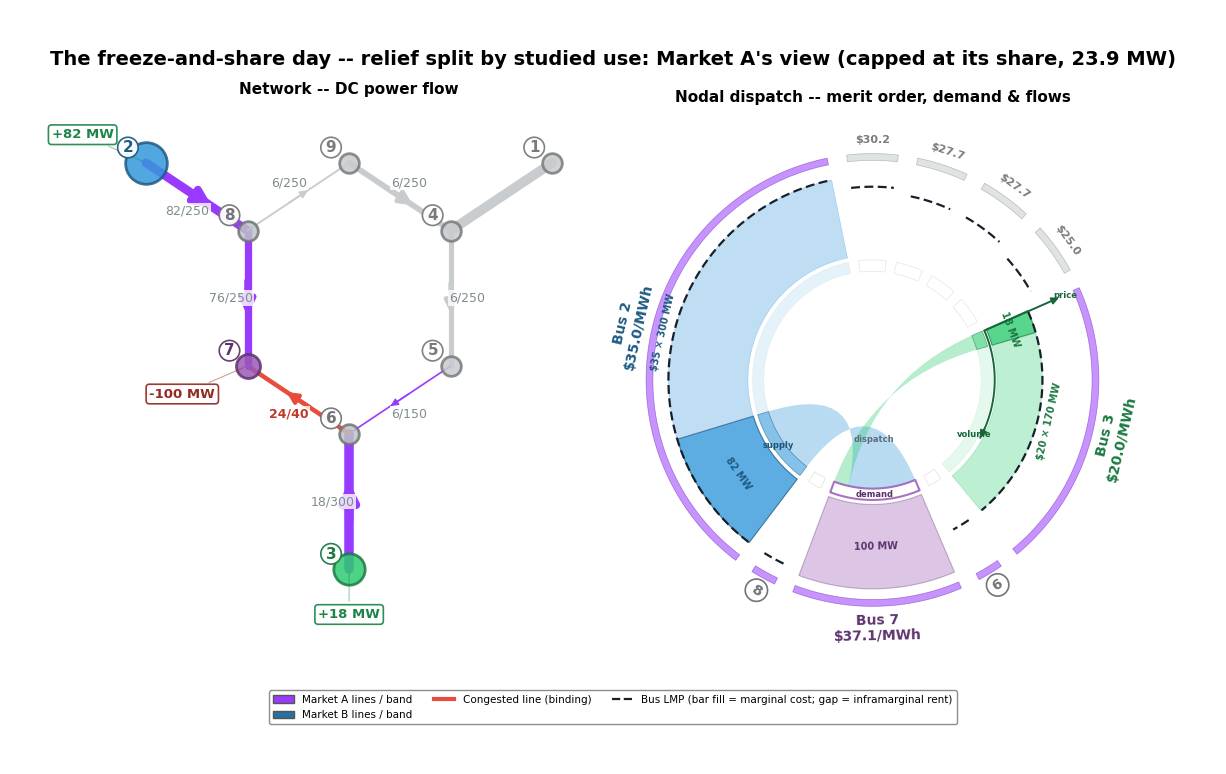

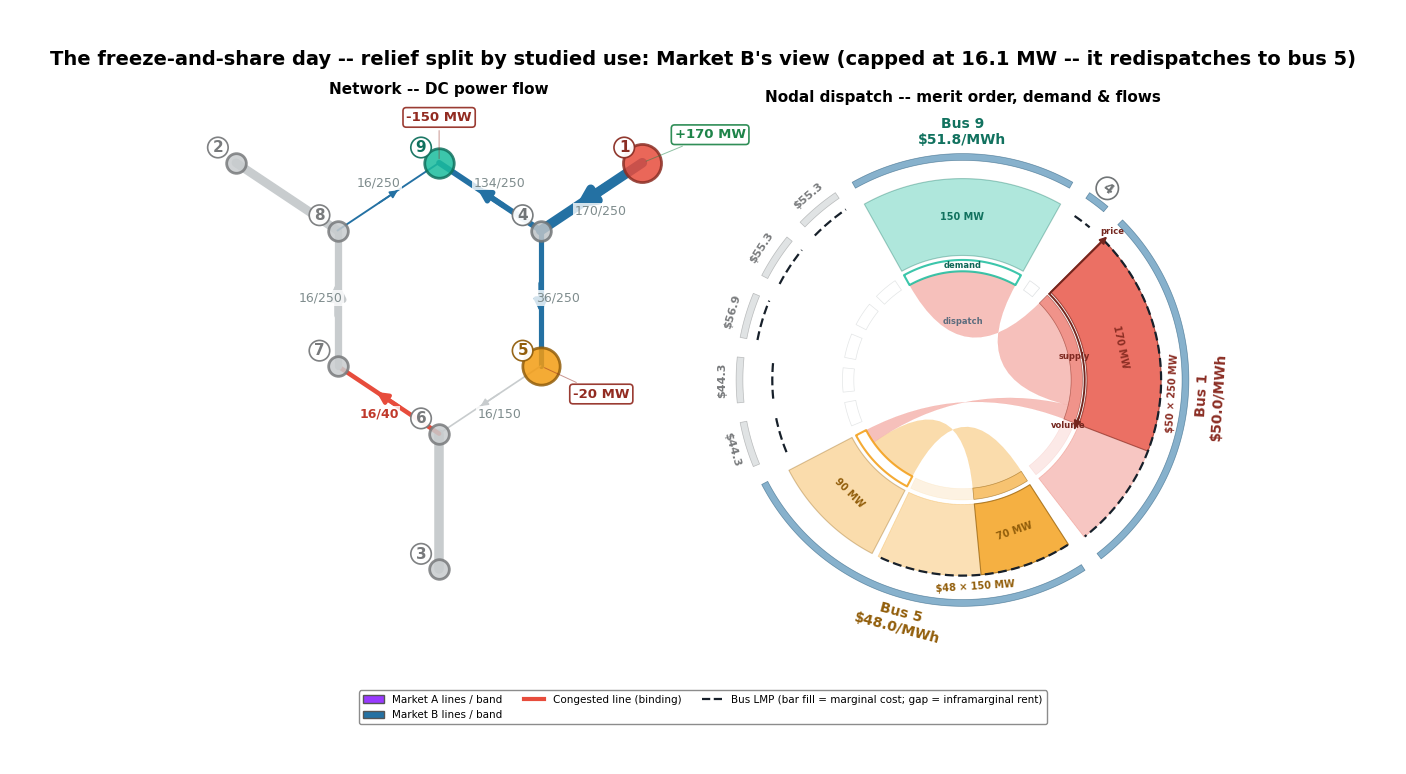

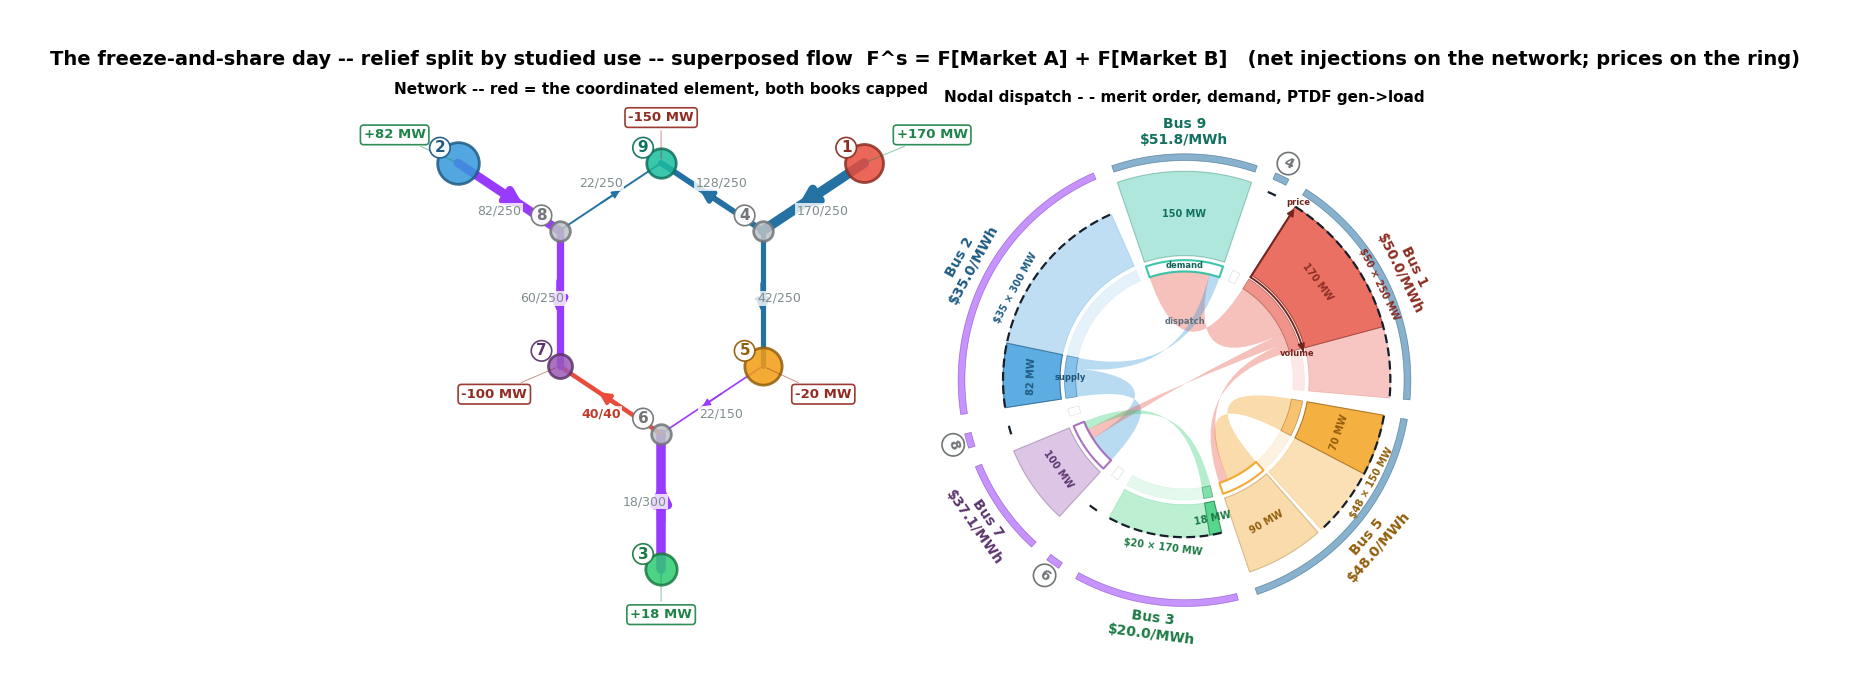

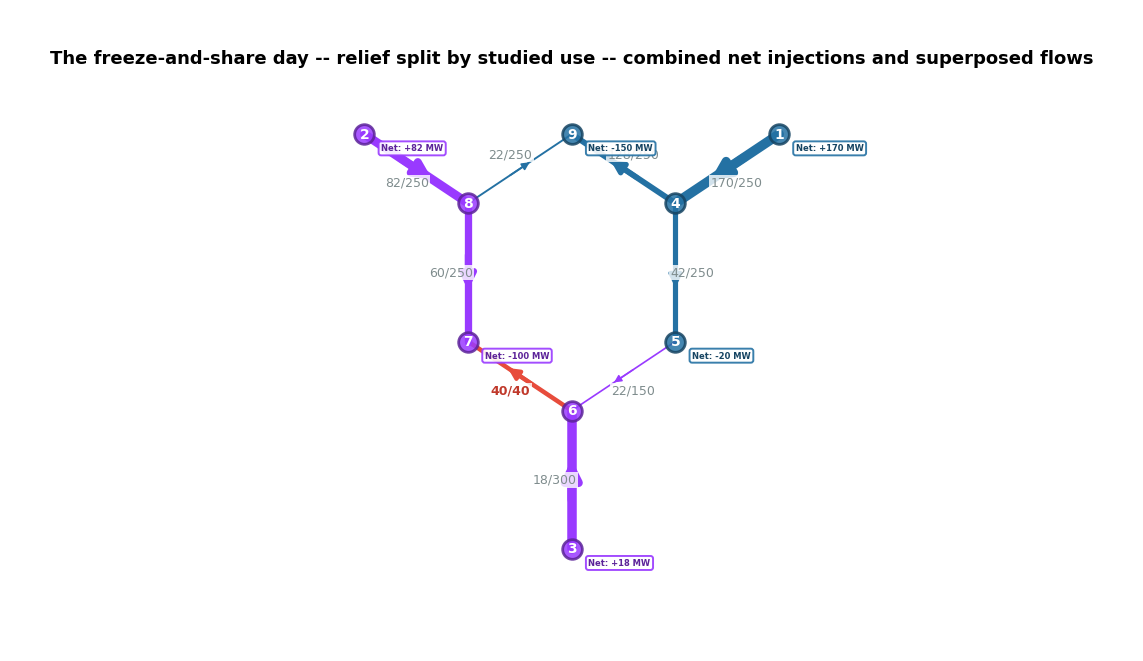

wrote presentation_exhibits\seams_cm_fs_freeze_and_share_settlement.csv and presentation_exhibits\seams_cm_fs_freeze_and_share_lines.csv

,market,LMP ($/MWh),gen (MW),paid to gen ($/h),load (MW),served (MW),paid by load ($/h)
bus,,,,,,,
1,Market B,50.0,169.7,8486.8,0.0,0.0,0.0
2,Market A,35.0,82.1,2873.2,0.0,0.0,0.0
3,Market A,20.0,17.9,358.2,0.0,0.0,0.0
4,Market B,50.0,0.0,0.0,0.0,0.0,0.0
5,Market B,48.0,70.3,3372.6,90.0,90.0,4320.0
6,Market A,20.0,0.0,0.0,0.0,0.0,0.0
7,Market A,37.13,0.0,0.0,100.0,100.0,3712.6
8,Market A,35.0,0.0,0.0,0.0,0.0,0.0
9,Market B,51.85,0.0,0.0,150.0,150.0,7777.2


,from,to,F[Market A],F[Market B],F^s (MW),rating,loading_%,overload,book flow Market A (MW),|mu| Market A ($/MWh),rent Market A ($/h),book flow Market B (MW),|mu| Market B ($/MWh),rent Market B ($/h)
line,,,,,,,,,,,,,,
line_0,1,4,0.0,169.7,169.7,250.0,68.0,False,0.0,0.0,0.0,169.7,0.0,0.0
line_1,4,5,6.0,35.8,41.8,250.0,17.0,False,6.0,0.0,0.0,35.8,0.0,0.0
line_2,5,6,6.0,16.1,22.1,150.0,15.0,False,6.0,0.0,0.0,16.1,0.0,0.0
line_3,3,6,17.9,-0.0,17.9,300.0,6.0,False,17.9,0.0,0.0,-0.0,0.0,0.0
line_4,6,7,23.9,16.1,40.0,40.0,100.0,False,23.9,20.1,481.2,16.1,14.8,237.7
line_5,7,8,-76.1,16.1,-60.0,250.0,24.0,False,-76.1,0.0,0.0,16.1,0.0,0.0
line_6,8,2,-82.1,0.0,-82.1,250.0,33.0,False,-82.1,0.0,0.0,0.0,0.0,0.0
line_7,8,9,6.0,16.1,22.1,250.0,9.0,False,6.0,0.0,0.0,16.1,0.0,0.0
line_8,9,4,6.0,-133.9,-127.9,250.0,51.0,False,6.0,0.0,0.0,-133.9,0.0,0.0


(                            market LMP ($/MWh) gen (MW) paid to gen ($/h) load (MW) served (MW)  paid by load ($/h)
 bus                                                                                                                
 1                         Market B        50.0    169.7            8486.8       0.0         0.0                 0.0
 2                         Market A        35.0     82.1            2873.2       0.0         0.0                 0.0
 3                         Market A        20.0     17.9             358.2       0.0         0.0                 0.0
 4                         Market B        50.0      0.0               0.0       0.0         0.0                 0.0
 5                         Market B        48.0     70.3            3372.6      90.0        90.0              4320.0
 6                         Market A        20.0      0.0               0.0       0.0         0.0                 0.0
 7                         Market A       37.13      0.0        

In [12]:
# Freeze-and-share in three frames, drawn on a stressed day -- the
# same one the incumbency-ratchet cell below uses (B's load heavy, its bus-5
# unit cheap). The drawn day above is mild: its exceedance is small enough that
# B's share cap never binds, so the rule would be invisible.
#
# Market B keeps its second unit here. The rule CAPS B, and a one-generation-bus
# book has no flow lever -- its loop flow is fixed by its load, so a cap could
# only be met by curtailment. With the bus-5 unit B REDISPATCHES against the
# cap, which is the mechanism this section is about.
STRESS_L9, STRESS_C5 = 150.0, 48.0
A_fs = engine_A()
B_fs = engine_B(load9=STRESS_L9, cost5=STRESS_C5)
rB_hat_s = solve_engine_dispatch(pt, B_fs, shed_price=150.0)
capsF, dF, shF = fs_caps(rA_hat.flow_own[L4], rB_hat_s.flow_own[L4])
rA_fs = clear_capped(engine_A(), capsF['Market A'])
rB_fs = clear_capped(engine_B(load9=STRESS_L9, cost5=STRESS_C5), capsF['Market B'])
_shed = sum(rB_fs.shed_by_bus.values())
print(f"stressed day: B load9 {STRESS_L9:.0f} MW, bus-5 unit ${STRESS_C5:.0f}/MWh")
print(f"studied flows: A {rA_hat.flow_own[L4]:+.1f}, B {rB_hat_s.flow_own[L4]:+.1f} "
      f"-> exceedance {dF:.1f} MW")
print(f"shares: A {shF['Market A']:.0%}, B {shF['Market B']:.0%}   "
      f"-> caps: A {capsF['Market A']:.1f}, B {capsF['Market B']:.1f} MW")
print(f"cleared: A {rA_fs.flow_own[L4]:+.1f}, B {rB_fs.flow_own[L4]:+.1f}, "
      f"superposed {rA_fs.flow_own[L4] + rB_fs.flow_own[L4]:+.1f} vs rating {RATE:.0f}")
print(f"B's response: bus-1 {rB_fs.gen_by_bus.get('1', 0.0):.1f} MW, "
      f"bus-5 {rB_fs.gen_by_bus.get('5', 0.0):.1f} MW, shed {_shed:.1f} MW "
      f"-- {'REDISPATCH' if _shed < 0.5 else 'CURTAILMENT'}")

LBL_F = 'The freeze-and-share day -- relief split by studied use'
own_view(net, pt, fp, 'Market A', A_fs, rA_fs, binding={L4},
         suptitle=f"{LBL_F}: Market A's view "
                  f"(capped at its share, {capsF['Market A']:.1f} MW)")
own_view(net, pt, fp, 'Market B', B_fs, rB_fs, binding={L4},
         suptitle=f"{LBL_F}: Market B's view "
                  f"(capped at {capsF['Market B']:.1f} MW -- it redispatches to bus 5)")
pf_f = combined_views(net, pt, fp, [(A_fs, rA_fs), (B_fs, rB_fs)], LBL_F,
                      binding={L4},
                      note='Network -- red = the coordinated element, both books capped')
export_pair(pt, [(A_fs, rA_fs), (B_fs, rB_fs)], 'fs_freeze_and_share')


In [13]:
# Detection risk, measured: the same stressed day over many study draws --
# how often does the study miss the trigger, and what does a miss cost?
N_STUDY = 200
rngs = np.random.default_rng(SEED_B + 1)
miss, hits, miss_bills = 0, 0, []
rA_blind = solve_engine_dispatch(pt, engine_A(), shed_price=150.0)
for _ in range(N_STUDY):
    l9h = l9_true + float(rngs.normal(0, STUDY_SD['load']))
    c5h = c5_true + float(rngs.normal(0, STUDY_SD['cost']))
    rBh = solve_engine_dispatch(pt, engine_B(load9=l9h, cost5=c5h), shed_price=150.0)
    if abs(rA_hat.flow_own[L4] + rBh.flow_own[L4]) >= TRIGGER_FRAC * RATE:
        hits += 1
    else:
        miss += 1
        fs_b = rA_blind.flow_own[L4] + rB_true_day.flow_own[L4]
        exc = max(0.0, abs(fs_b) - RATE)
        if exc > 1e-6:
            r_blk = BLOCK_MW * np.ceil(exc / BLOCK_MW)
            r_fin = rt_relief(pt, engine_A(), rA_blind, rB_true_day.flow_own,
                              ratings_override={L4: RATE - (r_blk - exc)})
            miss_bills.append(bill(r_fin) - bill(rA_blind))
print(f'the stressed day, studied {N_STUDY} times at D-1 forecast quality:')
print(f'  trigger fires {hits/N_STUDY:.0%} | study MISSES {miss/N_STUDY:.0%}')
if miss_bills:
    print(f'  a miss sends the day to blocks: host bill {np.mean(miss_bills):,.0f} $/h '
          f'(vs managing it ex ante)')
print('freeze-and-share inherits the under-accommodation risk: the rule is only as good as the study.')

the stressed day, studied 200 times at D-1 forecast quality:

  trigger fires 92% | study MISSES 8%

  a miss sends the day to blocks: host bill 218 $/h (vs managing it ex ante)

freeze-and-share inherits the under-accommodation risk: the rule is only as good as the study.

The trigger is a forecast object. On a stressed day the study still misses
some fraction of the time, at a miss rate set by the forecast spread against
the trigger margin. Each miss sends the day to the ex-post column: blocks, over-relief, and the
host market's bill. The quota carries no detection risk, and it
forgoes the savings of standing down in unstressed states.


In [14]:
# The incumbency ratchet: the same studied exceedance, two baseline
# definitions. (a) advisory baseline -- the studied flows; (b) prior-actual
# baseline -- yesterday's interval, when B happened to be running heavy.
# A clearly stressed study (heavy load, cheap bus-5 unit), so the exceedance
# and the caps are visibly at stake between the two baselines.
rB_str = solve_engine_dispatch(pt, engine_B(load9=150.0, cost5=48.0), shed_price=150.0)
fA_adv, fB_adv = rA_hat.flow_own[L4], rB_str.flow_own[L4]          # the advisory study
rB_hvy = solve_engine_dispatch(pt, engine_B(load9=170.0, cost5=46.0), shed_price=150.0)
fA_pri, fB_pri = rA_ref.flow_own[L4], rB_hvy.flow_own[L4]          # yesterday's actuals

rows = []
for name, fA0_, fB0_ in (('advisory baseline (studied flows)', fA_adv, fB_adv),
                         ('prior-actual baseline (B ran heavy yesterday)', fA_pri, fB_pri)):
    caps_, d_, sh_ = fs_caps(fA0_, fB0_)
    rA_ = clear_capped(engine_A(), caps_['Market A'])
    rB_ = clear_capped(engine_B(load9=150.0, cost5=48.0), caps_['Market B'])
    rows.append({'baseline': name, 'cap A (MW)': round(caps_['Market A'], 1),
                 'cap B (MW)': round(caps_['Market B'], 1),
                 'A bill ($/h)': round(bill(rA_)), 'B bill ($/h)': round(bill(rB_))})
pd.DataFrame(rows).set_index('baseline')

,cap A (MW),cap B (MW),A bill ($/h),B bill ($/h)
baseline,,,,
advisory baseline (studied flows),23.9,16.1,3231,11859
prior-actual baseline (B ran heavy yesterday),23.1,16.9,3249,11847


On the same line, under the same rule and the same shares, a different
baseline gives a different allocation. Under the prior-actual baseline the
market that was loading the line in the prior interval keeps the larger cap,
and the other market buys the difference in redispatch. Under a forecast
baseline the ratchet moves to whichever market can move the forecast: an
advisory baseline is gamed by bidding, and an actual-flow baseline is gamed
by dispatching. The baseline here refreshes at every event, so the effect is
milder than a decades-old freeze date. The incentive is of the same family,
which makes the baseline definition a design choice.


---

204 derives the failure modes these designs manage. 205 prices the
interchange side of the same seam. The scope of this notebook does not include the market-to-market settlement
layer, in which deviations from the entitlement settle at the constraint's
shadow price.
